<a href="https://colab.research.google.com/github/kaziH436/image-classifier-tensorflow/blob/main/Copy_of_GHW_IMAGE_CLASSIFIER.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Install Dependencies and Setup

In [ ]:
!pip install tensorflow opencv-python matplotlib #Tensorflow integration to help with training AI models

In [ ]:
!pip list

In [ ]:
import tensorflow as tf
import os

In [ ]:
import numpy as np
#NumPy is a library that stands for "Numerical Python". It provides support for multi-dimensional matrices, along with a collection of high-level mathematical functions to operate on these arrays.
from matplotlib import pyplot as plt

In [ ]:
%matplotlib inline

In [ ]:
# Avoid out-of-memory (OOM) errors by setting GPU Memory Consumption Growth
#"setting GPU memory consumption growth" refers to a strategy to manage how a program allocates memory on the GPU. It means allowing the GPU to dynamically allocate memory as needed, rather than pre-allocating all the memory at the start.
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

In [ ]:
tf.config.list_physical_devices('GPU')

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

# 2. Remove trash images

### Import keras and the MNIST Dataset

In [ ]:
(X_train,Y_train) , (X_test,Y_test) = tf.keras.datasets.mnist.load_data()
# we have two datasets here, X_train, Y_train and X_test,Y_test
print("X training original shape:", X_train.shape)
print("Y training original shape:", Y_train.shape)

In [ ]:
print(X_train[0]) #to get the images in matrix form
print("Shape: " + str(X_train[0].shape))

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 18

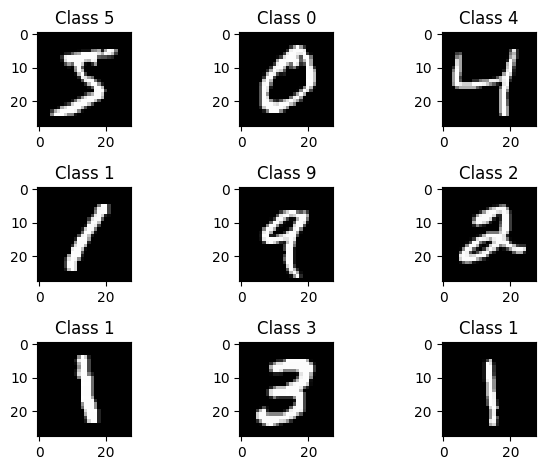

In [ ]:
for i in range(9): #this is where matplotlib is helpful
  plt.subplot(3,3,i+1) #viewing images in matrix can be annoying so
  #we can use matplotlib to get the actual image from the matrix.
  plt.imshow(X_train[i], cmap='gray', interpolation='none')
  plt.title("Class {}".format(Y_train[i]))

plt.tight_layout()

In [ ]:
X_train = X_train.reshape(60000,784) #turns the image to an array so machines can work with it
X_test = X_test.reshape(10000,784)

In [ ]:
X_train = X_train.astype('float32') #we need to make sure numbers are in the right format
X_test = X_test.astype('float32') #by using the method astype of type float32
X_train /= 255 #to turn the values from 0-255 to 0 to 1 so binary numbers.
X_test /= 255 #this  applies to each element of the array

In [ ]:
print("training matrix shape:", X_train.shape)

training matrix shape: (60000, 784)


In [ ]:
nb_calsses = 10 #the number of classes
#refer to one hot coding in the google docs
Y_train = tf.keras.utils.to_categorical(Y_train, nb_calsses) #each 0 and 1 value will be elements in an array
Y_test = tf.keras.utils.to_categorical(Y_test, nb_calsses)

In [ ]:
Y_train


array([[[1., 0., 0., ..., 0., 0., 0.],
        [1., 0., 0., ..., 0., 0., 0.],
        [1., 0., 0., ..., 0., 0., 0.],
        ...,
        [1., 0., 0., ..., 0., 0., 0.],
        [1., 0., 0., ..., 0., 0., 0.],
        [1., 0., 0., ..., 0., 0., 0.]],

       [[0., 1., 0., ..., 0., 0., 0.],
        [1., 0., 0., ..., 0., 0., 0.],
        [1., 0., 0., ..., 0., 0., 0.],
        ...,
        [1., 0., 0., ..., 0., 0., 0.],
        [1., 0., 0., ..., 0., 0., 0.],
        [1., 0., 0., ..., 0., 0., 0.]],

       [[1., 0., 0., ..., 0., 0., 0.],
        [1., 0., 0., ..., 0., 0., 0.],
        [1., 0., 0., ..., 0., 0., 0.],
        ...,
        [1., 0., 0., ..., 0., 0., 0.],
        [1., 0., 0., ..., 0., 0., 0.],
        [1., 0., 0., ..., 0., 0., 0.]],

       ...,

       [[1., 0., 0., ..., 0., 0., 0.],
        [1., 0., 0., ..., 0., 0., 0.],
        [1., 0., 0., ..., 0., 0., 0.],
        ...,
        [1., 0., 0., ..., 0., 0., 0.],
        [1., 0., 0., ..., 0., 0., 0.],
        [1., 0., 0., ..., 0., 0.

In [ ]:
model = tf.keras.Sequential([ #building neural networks
                              tf.keras.layers.Dense(512, input_shape=(784,)),
                              tf.keras.layers.Activation('relu'),
                              tf.keras.layers.Dropout(0.2),
                              tf.keras.layers.Dense(10),
                              tf.keras.layers.Activation('softmax')
])

In [ ]:
model.summary() #gives the characteristics of my model

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 512)                 │         401,920 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           5,130 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_1 (Activation)            │ (None, 10)                  │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 407,050 (1.55 MB)

 Trainable params: 407,050 (1.55 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
#compiling our model
# the loss function cossentropy is for comparing two probability distributions, so it checks how different your probability distribution is from your target distribution

In [ ]:
model.fit(X_train, Y_train,
          batch_size=128, epochs=4, verbose=1,
          validation_data=(X_test, Y_test))

In [ ]:
score = model.evaluate(X_test, Y_test, verbose=0) #tests the trained model
print(score)
print('Test score:', score[0])
print('Test accuracy:', score[1])


In [ ]:
predictions = model.predict(X_test) #looking at the predictions of both the testing  and training data
print(predictions[0])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
[0.08336238 0.13922681 0.13331924 0.1526068  0.06626773 0.11939958
 0.08577068 0.06292319 0.08065303 0.07647056]


In [ ]:
predicted_classes = np.argmax(predictions, axis=-1) #argmax ??
print(predicted_classes)

[3 5 5 ... 4 4 3]


In [ ]:
Y_test = np.argmax(Y_test, axis=-1)
correct_indices = np.nonzero(predicted_classes == Y_test)[0]
incorrect_indices = np.nonzero(predicted_classes != Y_test)[0]
plt.figure()
for i, correct in enumerate(correct_indices[:9]):
    plt.subplot(3,3,i+1)
    plt.imshow(X_test[correct].reshape(28,28), cmap='gray', interpolation='none')
    plt.title("Predicted {}, Class {}".format(predicted_classes[correct], Y_test[correct]))
plt.tight_layout()